<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Weather Service](https://github.com/Query-farm/vgi-nws)

Explore US weather alerts, observations, forecast grids, bulletins, and river conditions.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nws/blob/main/notebooks/02_a_nearby_station_can_still_be_stale.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nws/blob/main/notebooks/README.md)


## 02 · A nearby station can still be stale

Which returned station has a recent observation, and what does its forecast context
actually describe? We resolve a point's office/zone, inspect station identities, and
compare observation times with an explicit scenario clock. Then keep station observations,
hourly forecasts and day/night summaries separate.

This is a **synthetic teaching scenario**, not actual weather at Charlottesville.
The freshness cutoff is a local analysis choice, not an NWS quality or safety rule.

### Choose an observation-age limit

`MAX_AGE_HOURS = 1` admits observations no more than one hour old at the fixed
**2026-01-02 12:00 UTC** scenario time. The experiment uses **4**. Both stations and
all source documents are fetched regardless of this cutoff; only local selection changes.
A recent timestamp is necessary for this shortlist, but does not prove representativeness
or quality. Missing gust/precipitation measurements remain NULL.

In [1]:
MAX_AGE_HOURS = 1  # Experiment: 4; supported range 0–24 hours

### Run independently

Read the saved results on GitHub or choose **Open in Colab** and Run All. The brief
base install preserves compatible preloaded plotting and kernel libraries. Local
publication uses the optional `[runner]` extra. Initial packages, verified companions,
VGI and native worker download need internet. No worker checkout, Bun or source build
is required. Hosted Colab is not tested; a fresh preloaded Python 3.12 notebook-only
execution checks the common setup path. [Detailed setup and provenance](README.md).

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.40":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.40"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.40":
    raise RuntimeError("Install shared tools 0.3.40, restart, and Run All.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("nws")
from scenario_source import ScenarioSource

%matplotlib inline
theme()
session = connect(globals())
con = session.connection
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert con.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
source = ScenarioSource()
Path("artifacts").mkdir(exist_ok=True)
PROVENANCE = "Source: synthetic NOAA-shaped teaching inputs · 2 January 2026 UTC · not live conditions"

if type(MAX_AGE_HOURS) not in (int, float) or not np.isfinite(MAX_AGE_HOURS) or not 0 <= MAX_AGE_HOURS <= 24:
    raise ValueError("MAX_AGE_HOURS must be finite from 0 through 24")

### Source boundary

Every value in this story is **synthetic**. The real released NWS worker parses
NOAA-shaped documents served only on loopback; all ten upstream roots are scoped to
that local service and unknown requests fail. No real alert, gauge condition or forecast
is represented. Canonical `source_url` values are emitted by the worker even in this
mode: they describe product routes, not proof of a live request. `fetched_at` is the
local read time. The fixture's fixed scenario time is **2026-01-02 12:00 UTC**.

Shared setup uses an empty temporary SQL-secret directory, disables persistence and
JupySQL default connection autoload, and fixes the connection timezone to UTC. No key,
saved secret or account write is involved. Cleanup closes the connection/service and
restores the temporary process environment.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nws' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-nws@v0.4.0');

,Success


### Resolve context, then inspect the returned stations

A point resolution is a forecast-grid mapping, not an observation or exact address.
Its office and forecast-zone identifiers link to descriptive metadata. Zone index
geometry may be NULL even when the individual zone provides a boundary. The two station
records are candidates associated with that grid; their order does not imply distance
or freshness. Inspect each identifier and elevation before fetching observations.

In [5]:
%%sql
CREATE TABLE location AS SELECT * FROM nws.main.point(38.0293,-78.4767);
CREATE TABLE candidate_stations AS SELECT * FROM nws.main.stations_at(38.0293,-78.4767);
CREATE TABLE station_details AS
SELECT d.* FROM candidate_stations s,LATERAL nws.main.station(s.station_id) d;
CREATE TABLE zone_index AS SELECT * FROM nws.main.zones('forecast',state:='VA');
CREATE TABLE zone_detail AS SELECT z.* FROM location p,LATERAL nws.main.zone('forecast',p.forecast_zone) z;
CREATE TABLE office_detail AS SELECT o.* FROM location p,LATERAL nws.main.office(p.office_id) o;
CREATE TABLE terminology AS SELECT * FROM nws.main.glossary();
SELECT p.city,p.office_id,o.name AS office_name,p.forecast_zone,z.name AS zone_name,
 i.geometry_json IS NOT NULL AS index_has_boundary,z.geometry_json IS NOT NULL AS detail_has_boundary
FROM location p JOIN office_detail o USING(office_id)
JOIN zone_detail z ON z.zone_id=p.forecast_zone JOIN zone_index i USING(zone_id);
SELECT station_id,name,elevation_m,latitude,longitude FROM station_details ORDER BY station_id;
SELECT term,definition FROM terminology WHERE term='Frost';

,term,definition
0,Frost,Synthetic glossary entry: ice crystals on a su...


### Keep source values, normalization and time separate

Materialize both observation histories and latest observations, plus two forecast products.
The synthetic histories deliberately encode temperatures using °F, kelvin and °C; the
worker converts supported units to °C while retaining the original measurement JSON.
An 18 km/h wind becomes 5 m/s. NULL gust and hourly precipitation values do not become zero.

`latest_observation` means latest available at that station. It is not a synchronized
cross-station snapshot. Hourly forecast intervals begin at the scenario time; day/night
periods are longer summaries and are not expanded into hourly values. The glossary's
frost description does not make a grid air temperature into proof of surface frost.

In [6]:
%%sql
CREATE TABLE history AS
SELECT * FROM nws.main.observations('KCHO',page_size:=2)
UNION ALL SELECT * FROM nws.main.observations('KEXA',page_size:=2);
CREATE TABLE latest AS
SELECT s.station_id,l.* FROM candidate_stations s,LATERAL nws.main.latest_observation(s.station_id) l;
CREATE TABLE period_forecast AS SELECT * FROM nws.main.forecast(38.0293,-78.4767);
CREATE TABLE hourly_forecast AS SELECT * FROM nws.main.forecast_hourly(38.0293,-78.4767);
CREATE TABLE recency AS
SELECT station_id,observed_at,temperature_c,wind_speed_m_s,wind_gust_m_s,precipitation_1h_mm,
 date_diff('second',observed_at,TIMESTAMPTZ '2026-01-02 12:00:00+00')/3600.0 AS age_hours,
 age_hours BETWEEN 0 AND {{MAX_AGE_HOURS}} AS selected FROM latest;
SELECT * FROM recency ORDER BY station_id;
SELECT 'day/night' AS product,count(*) AS rows,min(temperature_c) AS min_c,max(temperature_c) AS max_c,
 min(date_diff('minute',start_time,end_time))/60.0 AS shortest_hours FROM period_forecast
UNION ALL SELECT 'hourly',count(*),min(temperature_c),max(temperature_c),
 min(date_diff('minute',start_time,end_time))/60.0 FROM hourly_forecast;
SELECT station,observed_at,temperature_c,json_extract_string(measurements_json,'$.temperature.unitCode') AS source_unit,
 wind_speed_m_s,wind_gust_m_s,precipitation_1h_mm FROM history ORDER BY station,observed_at;

,station,observed_at,temperature_c,source_unit,wind_speed_m_s,wind_gust_m_s,precipitation_1h_mm
0,https://api.weather.gov/stations/KCHO,2026-01-02 10:00:00+00:00,0.0,wmoUnit:degF,5.0,NaN,NaN
1,https://api.weather.gov/stations/KCHO,2026-01-02 11:00:00+00:00,1.0,wmoUnit:K,5.0,NaN,NaN
2,https://api.weather.gov/stations/KCHO,2026-01-02 12:00:00+00:00,2.0,wmoUnit:degC,5.0,NaN,NaN
3,https://api.weather.gov/stations/KEXA,2026-01-02 07:00:00+00:00,0.0,wmoUnit:degF,5.0,NaN,NaN
4,https://api.weather.gov/stations/KEXA,2026-01-02 08:00:00+00:00,1.0,wmoUnit:K,5.0,NaN,NaN
5,https://api.weather.gov/stations/KEXA,2026-01-02 09:00:00+00:00,2.0,wmoUnit:degC,5.0,NaN,NaN


In [7]:
%%sql recency <<
SELECT * FROM recency ORDER BY station_id;

In [8]:
display(recency)
selected = recency.loc[recency.selected, "station_id"].tolist()
prose(
    f"At the fixed scenario clock, **{len(selected)} of {len(recency)} stations** pass the **{MAX_AGE_HOURS:g}-hour** age limit: **{', '.join(selected) or 'none'}**. The two latest values have ages **{', '.join(f'{x:g}' for x in recency.age_hours)} hours**; identical temperature values would not make their timestamps identical. Both retain missing gust and hourly-precipitation values."
)

,station_id,observed_at,temperature_c,wind_speed_m_s,wind_gust_m_s,precipitation_1h_mm,age_hours,selected
0,KCHO,2026-01-02 12:00:00+00:00,2.0,5.0,NaN,NaN,0.0,True
1,KEXA,2026-01-02 09:00:00+00:00,2.0,5.0,NaN,NaN,3.0,False


At the fixed scenario clock, **1 of 2 stations** pass the **1-hour** age limit: **KCHO**. The two latest values have ages **0, 3 hours**; identical temperature values would not make their timestamps identical. Both retain missing gust and hourly-precipitation values.

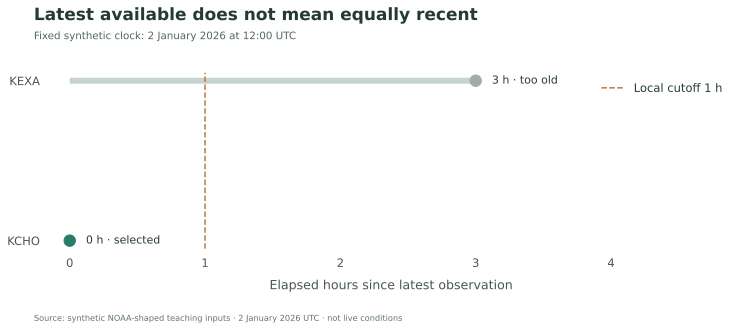

In [9]:
fig, ax = plt.subplots(figsize=(10.8, 4.8))
y = np.arange(len(recency))
ax.hlines(y, 0, recency.age_hours, color="#C7D4CE", linewidth=6)
ax.scatter(
    recency.age_hours, y, s=130, color=["#287D68" if x else "#A0ACA7" for x in recency.selected], zorder=3
)
for i, r in enumerate(recency.itertuples()):
    ax.text(
        r.age_hours + 0.12, i, f"{r.age_hours:g} h · {'selected' if r.selected else 'too old'}", va="center"
    )
ax.axvline(MAX_AGE_HOURS, color="#B87845", linestyle="--", label=f"Local cutoff {MAX_AGE_HOURS:g} h")
ax.set(
    yticks=y,
    yticklabels=recency.station_id,
    xlabel="Elapsed hours since latest observation",
    xlim=(-0.15, max(4.9, MAX_AGE_HOURS + 1)),
)
ax.legend(loc="upper right")
finish(
    fig,
    "Latest available does not mean equally recent",
    "Fixed synthetic clock: 2 January 2026 at 12:00 UTC",
    PROVENANCE,
    name=f"station-age-{MAX_AGE_HOURS:g}",
)

In [10]:
%%sql periods <<
SELECT start_time,end_time,temperature_c,'day/night' AS product FROM period_forecast UNION ALL SELECT start_time,end_time,temperature_c,'hourly' FROM hourly_forecast ORDER BY product,start_time;

,start_time,end_time,temperature_c,product
0,2026-01-02 12:00:00+00:00,2026-01-03 00:00:00+00:00,0.0,day/night
1,2026-01-03 00:00:00+00:00,2026-01-03 12:00:00+00:00,5.0,day/night
2,2026-01-02 12:00:00+00:00,2026-01-02 13:00:00+00:00,0.0,hourly
3,2026-01-02 13:00:00+00:00,2026-01-02 14:00:00+00:00,1.0,hourly
4,2026-01-02 14:00:00+00:00,2026-01-02 15:00:00+00:00,2.0,hourly
5,2026-01-02 15:00:00+00:00,2026-01-02 16:00:00+00:00,3.0,hourly
6,2026-01-02 16:00:00+00:00,2026-01-02 17:00:00+00:00,4.0,hourly
7,2026-01-02 17:00:00+00:00,2026-01-02 18:00:00+00:00,5.0,hourly


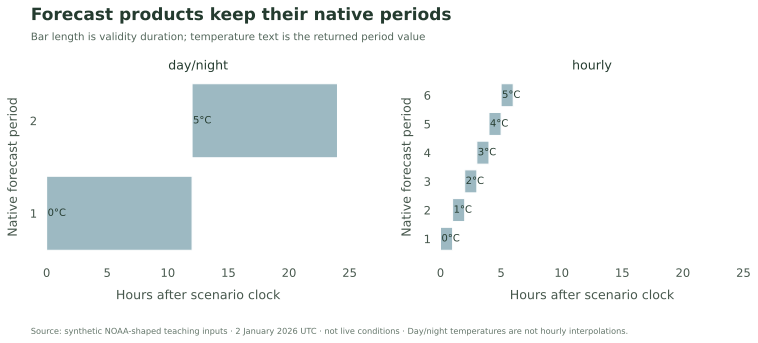

In [11]:
display(periods)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, product in zip(axes, ["day/night", "hourly"], strict=True):
    rows = periods[periods["product"] == product]
    for i, r in enumerate(rows.itertuples()):
        ax.barh(
            i,
            (r.end_time - r.start_time).total_seconds() / 3600,
            left=(r.start_time - pd.Timestamp("2026-01-02T12:00:00Z")).total_seconds() / 3600,
            color="#739BA8",
            alpha=0.7,
        )
        ax.text(
            (r.start_time - pd.Timestamp("2026-01-02T12:00:00Z")).total_seconds() / 3600 + 0.08,
            i,
            f"{r.temperature_c:g}°C",
            va="center",
            fontsize=10,
        )
    ax.set(
        title=product,
        xlabel="Hours after scenario clock",
        ylabel="Native forecast period",
        yticks=range(len(rows)),
        yticklabels=range(1, len(rows) + 1),
        xlim=(0, 25),
    )
finish(
    fig,
    "Forecast products keep their native periods",
    "Bar length is validity duration; temperature text is the returned period value",
    PROVENANCE + " · Day/night temperatures are not hourly interpolations.",
    name="forecast-product-periods",
)

### Check identity and the shortlist boundary

These controls check the fixed synthetic population, unit normalization and missing values.
They deliberately do not certify actual station quality or forecast accuracy. The forecast
products are contextual outputs, not observations used to score one another.

In [12]:
%%sql checks <<
SELECT 'two distinct station identifiers' AS check_name,count(*)=2 AND count(DISTINCT station_id)=2 AS passed FROM station_details
UNION ALL SELECT 'station metadata agrees',NOT EXISTS((SELECT station_id,elevation_m FROM station_details EXCEPT SELECT station_id,elevation_m FROM candidate_stations) UNION ALL (SELECT station_id,elevation_m FROM candidate_stations EXCEPT SELECT station_id,elevation_m FROM station_details))
UNION ALL SELECT 'boundary supplied only by detail',(SELECT count(*)=1 AND count(geometry_json)=0 FROM zone_index) AND (SELECT count(*)=1 AND count(geometry_json)=1 FROM zone_detail)
UNION ALL SELECT 'six unique station-times',count(*)=6 AND count(DISTINCT(station,observed_at))=6 FROM history
UNION ALL SELECT 'three source temperature units',count(DISTINCT json_extract_string(measurements_json,'$.temperature.unitCode'))=3 FROM history
UNION ALL SELECT 'temperature conversion values',min(temperature_c)=0 AND max(temperature_c)=2 FROM history
UNION ALL SELECT 'wind normalization',bool_and(abs(wind_speed_m_s-5)<1e-12) FROM history
UNION ALL SELECT 'missing measurements retained',count(wind_gust_m_s)=0 AND count(precipitation_1h_mm)=0 FROM history
UNION ALL SELECT 'latest equals history maximum',NOT EXISTS(SELECT 1 FROM latest l WHERE l.observed_at<>(SELECT max(h.observed_at) FROM history h WHERE h.station=l.station))
UNION ALL SELECT 'fixed observed ages',min(age_hours)=0 AND max(age_hours)=3 FROM recency
UNION ALL SELECT 'selection implements local age rule',bool_and(selected=(age_hours BETWEEN 0 AND {{MAX_AGE_HOURS}})) FROM recency
UNION ALL SELECT 'forecast periods remain distinct',(SELECT count(*)=2 FROM period_forecast) AND (SELECT count(*)=6 FROM hourly_forecast)
UNION ALL SELECT 'forecast missing probability retained',(SELECT count(*) FILTER(WHERE precipitation_probability_pct IS NULL)=1 FROM period_forecast) AND (SELECT count(*) FILTER(WHERE precipitation_probability_pct IS NULL)=1 FROM hourly_forecast);

In [13]:
assert len(checks) == 13 and checks.passed.all()
requests = source.audit()
display(checks)
prose(
    f"All **{len(checks)} SQL checks** pass. The synthetic service handled **{len(requests)} bounded requests**; main worker caching can reuse shared context documents. No remote NOAA condition was queried."
)
Path("artifacts/station-audit.json").write_text(
    json.dumps(
        {
            "parameter": MAX_AGE_HOURS,
            "recency": recency.to_dict("records"),
            "periods": periods.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,two distinct station identifiers,True
1,station metadata agrees,True
2,boundary supplied only by detail,True
3,six unique station-times,True
4,three source temperature units,True
5,temperature conversion values,True
6,wind normalization,True
7,missing measurements retained,True
8,latest equals history maximum,True
9,fixed observed ages,True


All **13 SQL checks** pass. The synthetic service handled **16 bounded requests**; main worker caching can reuse shared context documents. No remote NOAA condition was queried.

5384

### Experiment: admit older observations

Change only **MAX_AGE_HOURS from 1 to 4**. The selected station count should change
from one to two while all timestamps, ages, temperatures, NULL fields and forecast
periods stay fixed. The native-period figure should be identical. A looser local age
rule enlarges the shortlist; it does not make the older observation fresher or turn
synthetic measurements into actual weather. Restore 1 afterward.

In [14]:
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nws](https://github.com/Query-farm/vgi-nws)